# ถ้าเกิดอุบัติเหตุตรงนี้ จะร้ายแรงไหม (Severity Map)
งานนี้เป็น **Classification** เพราะคำตอบมี 2 แบบ คือ "ร้ายแรง" หรือ "ไม่ร้ายแรง" และโมเดลตอบเป็นโอกาส เช่น 41%

**Pain point:** การวางจุดจอดรถกู้ชีพและจุดตรวจมักดูจากจำนวนเหตุ แต่จุดที่เกิดเหตุบ่อยอาจเป็นเหตุเล็กน้อย ส่วนจุดที่เกิดไม่บ่อยอาจร้ายแรงเกือบทุกครั้ง

**ผู้ใช้:** เจ้าหน้าที่ที่วางแผนจุดจอดรถกู้ชีพและจุดตรวจของจังหวัด

**เป้าหมาย:** ตอบว่า "ถ้าเกิดอุบัติเหตุที่จุดนี้ เวลานี้ กับรถประเภทนี้ มีโอกาสร้ายแรงกี่ %"

**ร้ายแรง** หมายถึง มีผู้เสียชีวิตหรือผู้บาดเจ็บสาหัสอย่างน้อย 1 คน

**สิ่งที่จะทำ:** อ่านข้อมูล → สำรวจ → คลีน → ดูกราฟ → เตรียม feature → ฝึก 4 โมเดล → เลือก → ประเมิน → บันทึกโมเดลให้เว็บใช้

**ข้อควรรู้:** โมเดลนี้ไม่ได้บอกโอกาสที่จะ "เกิด" อุบัติเหตุ เพราะข้อมูลมีเฉพาะเหตุที่เกิดและถูกบันทึกแล้ว

รันเซลล์จากบนลงล่าง ข้อมูลดิบอยู่ใน `data/datagov/` ส่วนไฟล์ที่ notebook นี้สร้างจะอยู่ใน `data/explore_idea/severity_map/`

## 1. อ่านข้อมูล
ใช้ข้อมูลอุบัติเหตุทั้งประเทศปี 2563–2569 (ค.ศ. 2020–2026) ปี 2569 มีถึงเดือนตุลาคม

ไม่ใช้ปี 2562 (2019) เพราะไฟล์ปีนั้นไม่มีคอลัมน์ผู้บาดเจ็บสาหัส จึงสร้างคำตอบ "ร้ายแรง" ไม่ได้

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from matplotlib import font_manager
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, confusion_matrix
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

pd.set_option("display.max_rows", 20)
pd.set_option("display.max_columns", 12)

In [2]:
# เลือกฟอนต์ที่แสดงภาษาไทยในกราฟได้
# ถ้าเครื่องไม่มีฟอนต์เหล่านี้ กราฟยังวาดได้ แต่ตัวอักษรไทยอาจเป็นกล่องสี่เหลี่ยม
installed_fonts = []
for font in font_manager.fontManager.ttflist:
    installed_fonts.append(font.name)

for font_name in ["Thonburi", "Tahoma", "Sarabun", "Noto Sans Thai"]:
    if font_name in installed_fonts:
        plt.rcParams["font.family"] = font_name
        break

In [3]:
# หาโฟลเดอร์โปรเจกต์ โดยเดินขึ้นไปทีละชั้นจนเจอโฟลเดอร์ data/datagov
project_dir = Path.cwd().resolve()
while not (project_dir / "data" / "datagov").is_dir():
    if project_dir == project_dir.parent:
        raise FileNotFoundError("ไม่พบโฟลเดอร์ data/datagov")
    project_dir = project_dir.parent

raw_dir = project_dir / "data" / "datagov"
idea_dir = project_dir / "data" / "explore_idea" / "severity_map"
clean_dir = idea_dir / "clean"
feature_dir = idea_dir / "features"
model_dir = idea_dir / "model"

for folder in [clean_dir, feature_dir, model_dir]:
    folder.mkdir(parents=True, exist_ok=True)

years = [2020, 2021, 2022, 2023, 2024, 2025, 2026]

In [4]:
# ปี 2026 ตั้งชื่อคอลัมน์บางตัวต่างจากปีอื่น จึงเปลี่ยนชื่อให้ตรงกันก่อนรวม
rename_2026 = {
    "บริเวณที่เกิดเหตุ/ลักษณะทาง": "บริเวณที่เกิดเหตุ",
    "ลักษณะการเกิดอุบัติเหตุ": "ลักษณะการเกิดเหตุ",
    "จำนวนผู้เสียชีวิต": "ผู้เสียชีวิต",
    "จำนวนผู้บาดเจ็บสาหัส": "ผู้บาดเจ็บสาหัส",
    "จำนวนผู้บาดเจ็บเล็กน้อย": "ผู้บาดเจ็บเล็กน้อย",
}

frames = []
for year in years:
    table = pd.read_csv(raw_dir / f"accident{year}.csv", dtype=str, encoding="utf-8-sig")
    if year == 2026:
        table = table.rename(columns=rename_2026)
    table["file_year"] = year
    frames.append(table)
    print(year, "จำนวนแถว:", len(table))

raw = pd.concat(frames, ignore_index=True)
print("รวมทั้งหมด:", len(raw), "แถว |", raw.shape[1], "คอลัมน์")

2020 จำนวนแถว: 21239
2021 จำนวนแถว: 20062
2022 จำนวนแถว: 20566


2023 จำนวนแถว: 23841
2024 จำนวนแถว: 23952
2025 จำนวนแถว: 23715


2026 จำนวนแถว: 18448
รวมทั้งหมด: 151823 แถว | 47 คอลัมน์


In [5]:
# เก็บเฉพาะคอลัมน์ที่ใช้ และเปลี่ยนชื่อให้เขียนโค้ดง่าย
column_names = {
    "วันที่เกิดเหตุ": "date_text",
    "เวลา": "time_text",
    "ACC_CODE": "acc_code",
    "สายทางหน่วยงาน": "road_type",
    "รหัสสายทาง": "route_code",
    "จังหวัด": "province",
    "รถคันที่1": "vehicle",
    "บริเวณที่เกิดเหตุ": "area",
    "ลักษณะการเกิดเหตุ": "crash_type_text",
    "สภาพอากาศ": "weather",
    "LATITUDE": "lat",
    "LONGITUDE": "lon",
    "ผู้เสียชีวิต": "deaths",
    "ผู้บาดเจ็บสาหัส": "serious_injuries",
    "ผู้บาดเจ็บเล็กน้อย": "minor_injuries",
}
selected_columns = ["file_year"] + list(column_names.keys())
data = raw[selected_columns].rename(columns=column_names)
data.head(3)

,file_year,date_text,time_text,acc_code,road_type,route_code,...,weather,lat,lon,deaths,serious_injuries,minor_injuries
0,2020,1/1/2020,0:05,3785916,ทางหลวง,4225,...,แจ่มใส,8.008887355,99.39067392,0,1,0
1,2020,1/1/2020,0:05,3786314,ทางหลวง,3473,...,แจ่มใส,15.6509403,99.47842239,0,1,0
2,2020,1/1/2020,0:15,575019,ทางหลวงชนบท,นภ.3038,...,แจ่มใส,17.191475,102.454305,1,0,0


## 2. สำรวจข้อมูลดิบ
ก่อนคลีน ต้องรู้ก่อนว่าข้อมูลมีปัญหาอะไรบ้าง ดู 3 เรื่อง คือ ค่าว่าง รูปแบบวันที่และเวลา และเหตุที่บันทึกซ้ำ

In [6]:
# ค่าว่างของแต่ละคอลัมน์ คิดเป็น %
missing_percent = data.isna().mean() * 100
missing_percent.round(1).sort_values(ascending=False)

acc_code            12.2
area                 8.5
crash_type_text      5.6
vehicle              1.5
province             1.3
weather              0.6
lat                  0.6
lon                  0.6
file_year            0.0
date_text            0.0
time_text            0.0
road_type            0.0
route_code           0.0
deaths               0.0
serious_injuries     0.0
minor_injuries       0.0
dtype: float64

In [7]:
# ดูตัวอย่างวันที่และเวลาของแต่ละปี จะเห็นว่าเขียนไม่เหมือนกัน
for year in years:
    rows = data.loc[data["file_year"].eq(year)]
    example = rows.iloc[500]
    print(year, "| วันที่:", example["date_text"], "| เวลา:", example["time_text"])

2020 | วันที่: 1/3/2020 | เวลา: 14:50
2021 | วันที่: 1/3/2021 | เวลา: 0:10
2022 | วันที่: 02/01/2022 | เวลา: 19:30
2023 | วันที่: 1/2/2023 | เวลา: 20:00
2024 | วันที่: 45294 | เวลา: 0.145833333
2025 | วันที่: 45660 | เวลา: 13:30
2026 | วันที่: 3/1/2026 | เวลา: 4:30


In [8]:
# รหัสเหตุ (acc_code) ที่ซ้ำกันในปีเดียวกัน แปลว่าเหตุเดียวถูกบันทึกมากกว่า 1 แถว
has_code = data["acc_code"].notna()
repeated_code = has_code & data.duplicated(["file_year", "acc_code"])
print("จำนวนแถวที่รหัสเหตุซ้ำ แยกตามปี")
print(repeated_code.groupby(data["file_year"]).sum())

จำนวนแถวที่รหัสเหตุซ้ำ แยกตามปี
file_year
2020       0
2021       0
2022       0
2023    1702
2024       0
2025       0
2026       0
dtype: int64


**สิ่งที่พบ**
- **ค่าว่าง:** `acc_code` ว่างทั้งปี 2026 เพราะไฟล์ปีนั้นไม่มีรหัสเหตุ ส่วน `area` (ลักษณะถนน) และ `crash_type_text` (ลักษณะการชน) ว่างประมาณ 6–9%
- **วันที่:** ปี 2020–2023 เขียนแบบ เดือน/วัน/ปี ปี 2024–2025 เป็นเลขลำดับวันของ Excel เช่น 45540 และปี 2026 เขียนแบบ วัน/เดือน/ปี
- **เวลา:** ปี 2024 เป็นเศษส่วนของวัน เช่น 0.5 หมายถึงเที่ยงวัน ปีอื่นเขียนแบบ ชั่วโมง:นาที
- **เหตุซ้ำ:** ปี 2023 มีรหัสเหตุซ้ำประมาณ 1,700 แถว

## 3. คลีนข้อมูล
แก้ทีละเรื่องตามที่พบในขั้นสำรวจ แล้วบันทึกผลเป็นไฟล์ใน `clean/`

### 3.1 วันที่
แปลงแยกปี เพราะแต่ละปีเขียนไม่เหมือนกัน

In [9]:
data["date"] = pd.NaT
for year in years:
    rows = data["file_year"].eq(year)
    values = data.loc[rows, "date_text"]
    if year in [2024, 2025]:
        # เลขลำดับวันของ Excel นับจากวันที่ 30 ธ.ค. 1899
        numbers = pd.to_numeric(values, errors="coerce")
        dates = pd.to_datetime(numbers, unit="D", origin="1899-12-30", errors="coerce")
    elif year == 2026:
        dates = pd.to_datetime(values, format="%d/%m/%Y", errors="coerce")
    else:
        dates = pd.to_datetime(values, format="%m/%d/%Y", errors="coerce")
    data.loc[rows, "date"] = dates

data["date"] = pd.to_datetime(data["date"])

# วันที่ต้องอ่านได้ และต้องอยู่ในปีเดียวกับไฟล์
valid_date = data["date"].notna() & data["date"].dt.year.eq(data["file_year"])
print("แถวที่วันที่ใช้ไม่ได้:", int((~valid_date).sum()))
data = data.loc[valid_date].copy()

แถวที่วันที่ใช้ไม่ได้: 1


### 3.2 เวลา
เก็บเฉพาะ "ชั่วโมง" (0–23) สำหรับปี 2024 ที่เป็นเศษส่วนของวัน ต้องแปลงเป็นนาทีแล้ว **ปัดเศษ** ก่อน

เหตุผล: เวลา 01:00 ถูกเก็บเป็น 0.041666667 ถ้าเอาไปคูณ 24 ตรง ๆ บางแถวจะได้ 0.99999 แล้วกลายเป็นชั่วโมง 0 ซึ่งผิด

In [10]:
def time_to_hour(text):
    if pd.isna(text):
        return np.nan
    if ":" in text:
        # แบบ ชั่วโมง:นาที เช่น "14:30" ได้ 14
        return int(text.split(":")[0])
    # แบบเศษส่วนของวัน เช่น "0.5" ได้ 720 นาที คือ 12 นาฬิกา
    minutes = round(float(text) * 24 * 60)
    hour = minutes // 60
    if hour > 23:
        hour = 23
    return hour


data["hour"] = data["time_text"].apply(time_to_hour)
print("ชั่วโมงต่ำสุด:", data["hour"].min(), "| สูงสุด:", data["hour"].max(), "| ค่าว่าง:", int(data["hour"].isna().sum()))

ชั่วโมงต่ำสุด: 0 | สูงสุด: 23 | ค่าว่าง: 0


### 3.3 เหตุที่บันทึกซ้ำ
ถ้ารหัสเหตุซ้ำกันในปีเดียวกัน เก็บไว้แถวเดียว แล้วลบแถวที่เหมือนกันทุกช่องอีกรอบ (สำหรับปี 2026 ที่ไม่มีรหัสเหตุ)

In [11]:
rows_before = len(data)

has_code = data["acc_code"].notna()
repeated_code = has_code & data.duplicated(["file_year", "acc_code"])
data = data.loc[~repeated_code].copy()

data = data.drop_duplicates().copy()

print("ก่อนลบ:", rows_before, "แถว | หลังลบ:", len(data), "แถว | ลบไป:", rows_before - len(data))

ก่อนลบ: 151822 แถว | หลังลบ: 150062 แถว | ลบไป: 1760


### 3.4 จำนวนผู้ประสบเหตุ และคำตอบ "ร้ายแรง"
แปลงข้อความเป็นตัวเลข แล้วสร้างคอลัมน์ `severe`
- `severe = 1` เมื่อมีผู้เสียชีวิตหรือผู้บาดเจ็บสาหัสอย่างน้อย 1 คน
- `severe = 0` ในกรณีอื่น

In [12]:
for column in ["deaths", "serious_injuries", "minor_injuries", "lat", "lon"]:
    data[column] = pd.to_numeric(data[column], errors="coerce")

print("ค่าว่างของจำนวนผู้ประสบเหตุ:")
print(data[["deaths", "serious_injuries", "minor_injuries"]].isna().sum())

data["severe"] = ((data["deaths"] + data["serious_injuries"]) > 0).astype(int)
print("สัดส่วนเหตุร้ายแรง:", round(data["severe"].mean() * 100, 1), "%")

ค่าว่างของจำนวนผู้ประสบเหตุ:
deaths              0
serious_injuries    0
minor_injuries      0
dtype: int64
สัดส่วนเหตุร้ายแรง: 18.5 %


### 3.5 พิกัด
พิกัดที่อยู่นอกกรอบประเทศไทยถือว่ากรอกผิด เปลี่ยนเป็นค่าว่าง แต่ยังเก็บแถวไว้ เพราะข้อมูลช่องอื่นยังใช้ได้

In [13]:
in_thailand = data["lat"].between(5.5, 20.6) & data["lon"].between(97.2, 105.8)
print("พิกัดที่ว่างหรืออยู่นอกประเทศไทย:", int((~in_thailand).sum()), "แถว")
data.loc[~in_thailand, ["lat", "lon"]] = np.nan

พิกัดที่ว่างหรืออยู่นอกประเทศไทย: 852 แถว


### 3.6 ข้อมูลแบบหมวดหมู่
- ตัดช่องว่างหัวท้าย และเติมค่าว่างด้วยคำว่า "ไม่ระบุ"
- จังหวัด "อยุธยา" กับ "พระนครศรีอยุธยา" คือจังหวัดเดียวกัน จึงรวมเป็นชื่อเดียว
- ชื่อประเภทรถยาวมาก จึงย่อให้สั้น
- ลักษณะถนนมี 80 กว่าแบบ และลักษณะการชนมี 150 กว่าแบบ เพราะแต่ละหน่วยงานใช้คำไม่เหมือนกัน จึงจัดเป็นกลุ่มใหญ่ไม่กี่กลุ่ม

In [14]:
data["province"] = data["province"].str.strip().replace({"อยุธยา": "พระนครศรีอยุธยา"}).fillna("ไม่ระบุ")
data["weather"] = data["weather"].str.strip().fillna("ไม่ระบุ")
data["road_type"] = data["road_type"].str.strip().fillna("ไม่ระบุ")

vehicle_names = {
    "รถปิคอัพบรรทุก 4 ล้อ": "รถกระบะ",
    "รถยนต์นั่งส่วนบุคคล/รถยนต์นั่งสาธารณะ": "รถยนต์นั่ง",
    "รถบรรทุกมากกว่า 10 ล้อ (รถพ่วง)": "รถบรรทุกมากกว่า 10 ล้อ",
    "รถบรรทุกมากกว่า 6 ล้อ ไม่เกิน 10 ล้อ": "รถบรรทุก 10 ล้อ",
    "รถปิคอัพโดยสาร": "รถกระบะโดยสาร",
    "รถอีแต๋น/เพื่อการเกษตร": "รถอีแต๋น",
}
data["vehicle"] = data["vehicle"].str.strip().replace(vehicle_names).fillna("ไม่ระบุ")
data["vehicle"].value_counts()

vehicle
รถกระบะ                   55023
รถยนต์นั่ง                39223
รถจักรยานยนต์             22040
รถบรรทุกมากกว่า 10 ล้อ    12201
รถบรรทุก 6 ล้อ             6070
รถบรรทุก 10 ล้อ            4484
อื่นๆ                      4438
ไม่ระบุ                    2064
รถตู้                      1893
รถโดยสารขนาดใหญ่            787
รถกระบะโดยสาร               551
รถสามล้อเครื่อง             494
รถจักรยาน                   354
คนเดินเท้า                  278
รถอีแต๋น                    108
รถสามล้อ                     54
Name: count, dtype: int64

In [15]:
# ลักษณะถนนเขียนเป็น "รูปร่างถนน+ความลาดชัน" เช่น "ทางโค้งกว้าง+ที่ลาดชัน"
def find_road_shape(text):
    if pd.isna(text):
        return "ไม่ระบุ"
    first_part = text.split("+")[0]
    if "โค้ง" in first_part:
        return "ทางโค้ง"
    if "ทางตรง" in first_part:
        return "ทางตรง"
    for word in ["แยก", "วงเวียน", "ทางร่วม", "กลับรถ", "Ramps"]:
        if word in first_part:
            return "ทางแยก"
    if "เชื่อม" in first_part or "เข้า" in first_part:
        return "ทางเชื่อม"
    return "อื่นๆ"


def find_road_slope(text):
    if pd.isna(text) or "+" not in text:
        return "ไม่ระบุ"
    second_part = text.split("+", 1)[1]
    if "ไม่มีความลาดชัน" in second_part or "ที่ราบ" in second_part:
        return "ทางราบ"
    return "ลาดชัน"


data["road_shape"] = data["area"].apply(find_road_shape)
data["road_slope"] = data["area"].apply(find_road_slope)
print(data["road_shape"].value_counts())
print()
print(data["road_slope"].value_counts())

road_shape
ทางตรง       107683
ทางโค้ง       22890
ไม่ระบุ       12784
ทางแยก         3787
ทางเชื่อม      2371
อื่นๆ           547
Name: count, dtype: int64

road_slope
ทางราบ     123438
ไม่ระบุ     18988
ลาดชัน       7636
Name: count, dtype: int64


In [16]:
# จัดลักษณะการชนเป็นกลุ่มใหญ่ ใช้ดูสถิติย้อนหลังเท่านั้น ไม่ใช้เป็น feature ของโมเดล
def find_crash_type(text):
    if pd.isna(text):
        return "ไม่ระบุ"
    if "คนเดินเท้า" in text:
        return "ชนคนเดินเท้า"
    if "ชนท้าย" in text:
        return "ชนท้าย"
    for word in ["พลิกคว่ำ", "ตกถนน", "เสียหลัก", "เสียการควบคุม", "ล้มเอง"]:
        if word in text:
            return "พลิกคว่ำ/ตกถนน"
    for word in ["ตรงกันข้าม", "ประสานงา", "ฝั่งตรงข้าม"]:
        if word in text:
            return "ชนประสานงา"
    for word in ["สิ่งกีดขวาง", "ชนเกาะ", "ชนป้าย", "จอด"]:
        if word in text:
            return "ชนสิ่งกีดขวาง"
    for word in ["ทางแยก", "เลี้ยว", "ด้านข้าง", "เฉี่ยว", "ทางตรงชน"]:
        if word in text:
            return "ชนด้านข้าง/ทางแยก"
    return "อื่นๆ"


data["crash_type"] = data["crash_type_text"].apply(find_crash_type)
data["crash_type"].value_counts()

crash_type
พลิกคว่ำ/ตกถนน       76140
ชนท้าย               46435
ไม่ระบุ               7635
ชนประสานงา            6611
ชนสิ่งกีดขวาง         6572
อื่นๆ                 3047
ชนด้านข้าง/ทางแยก     2092
ชนคนเดินเท้า          1530
Name: count, dtype: int64

### 3.7 บันทึกข้อมูลที่คลีนแล้ว
หนึ่งแถวคือหนึ่งเหตุ ไฟล์นี้ใช้ทั้งใน notebook และในเว็บ

In [17]:
clean_columns = ["file_year", "date", "hour", "province", "road_type", "route_code", "vehicle",
                 "weather", "road_shape", "road_slope", "crash_type", "lat", "lon",
                 "deaths", "serious_injuries", "minor_injuries", "severe"]
clean = data[clean_columns].rename(columns={"file_year": "year"}).reset_index(drop=True)

clean_path = clean_dir / "accidents_clean.csv"
clean.to_csv(clean_path, index=False, encoding="utf-8-sig")
print("บันทึกแล้ว:", clean_path.relative_to(project_dir), "|", len(clean), "แถว")
clean.head(3)

บันทึกแล้ว: data/explore_idea/severity_map/clean/accidents_clean.csv | 150062 แถว


,year,date,hour,province,road_type,route_code,...,lat,lon,deaths,serious_injuries,minor_injuries,severe
0,2020,2020-01-01,0,กระบี่,ทางหลวง,4225,...,8.008887,99.390674,0,1,0,1
1,2020,2020-01-01,0,นครสวรรค์,ทางหลวง,3473,...,15.650940,99.478422,0,1,0,1
2,2020,2020-01-01,0,หนองบัวลำภู,ทางหลวงชนบท,นภ.3038,...,17.191475,102.454305,1,0,0,1


## 4. ดูข้อมูลด้วยกราฟ
ดูว่าเหตุร้ายแรงมากับอะไรบ้าง เพื่อเลือกข้อมูลที่จะให้โมเดลใช้

### 4.1 เหตุร้ายแรงในแต่ละปี

In [18]:
by_year = clean.groupby("year")["severe"].agg(["size", "mean"])
by_year.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
by_year.round(3)

,จำนวนเหตุ,สัดส่วนร้ายแรง
year,,
2020,21238,0.220
2021,20062,0.203
2022,20566,0.181
2023,22139,0.176
2024,23952,0.182
2025,23715,0.169
2026,18390,0.168


**อ่านตาราง:** สัดส่วนเหตุร้ายแรงลดลงจาก 22.0% ในปี 2020 เหลือ 16.8% ในปี 2026 ภาพรวมทุกปีอยู่ที่ 18.5% ข้อมูลจึงไม่สมดุล คือเหตุไม่ร้ายแรงมีมากกว่าประมาณ 4 เท่า

ปี 2026 มีข้อมูลถึงเดือนตุลาคม จำนวนเหตุจึงน้อยกว่าปีอื่น

### 4.2 ประเภทรถ

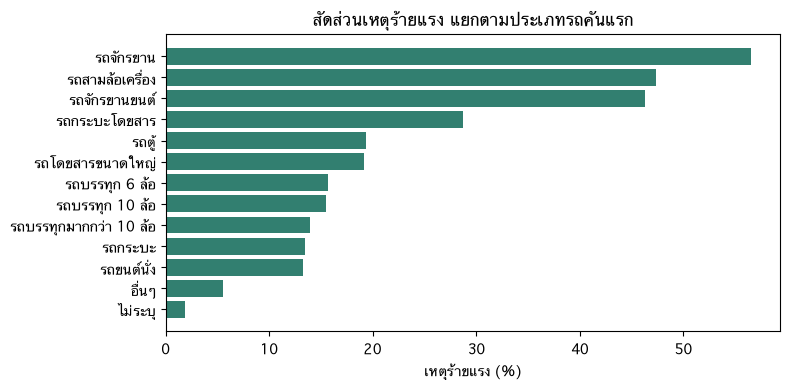

In [19]:
by_vehicle = clean.groupby("vehicle")["severe"].agg(["size", "mean"])
by_vehicle = by_vehicle.loc[by_vehicle["size"] >= 300].sort_values("mean")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(by_vehicle.index, by_vehicle["mean"] * 100, color="#327f70")
ax.set(xlabel="เหตุร้ายแรง (%)", title="สัดส่วนเหตุร้ายแรง แยกตามประเภทรถคันแรก")
plt.tight_layout()
plt.show()

**อ่านกราฟ:** รถที่ไม่มีตัวถังป้องกันผู้ขับขี่มีสัดส่วนเหตุร้ายแรงสูงกว่ามาก จักรยานยนต์อยู่ที่ประมาณ 46% ส่วนรถยนต์นั่งและรถกระบะอยู่ที่ประมาณ 13% ต่างกันราว 3.5 เท่า ประเภทรถจึงน่าจะเป็น feature ที่สำคัญ

กราฟแสดงเฉพาะประเภทรถที่มีตั้งแต่ 300 เหตุ เพื่อไม่ให้สัดส่วนแกว่งจากข้อมูลน้อย

### 4.3 ช่วงเวลา

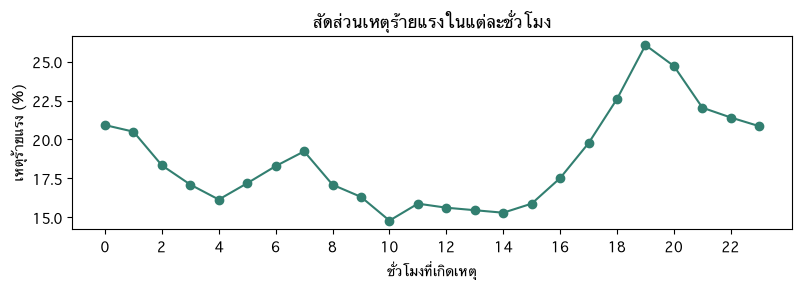

In [20]:
by_hour = clean.groupby("hour")["severe"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(by_hour.index, by_hour.values, marker="o", color="#327f70")
ax.set(xlabel="ชั่วโมงที่เกิดเหตุ", ylabel="เหตุร้ายแรง (%)", title="สัดส่วนเหตุร้ายแรงในแต่ละชั่วโมง")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

**อ่านกราฟ:** เหตุช่วงกลางวัน (10:00–15:00) ร้ายแรงน้อยที่สุด ประมาณ 15% และสูงสุดช่วงหัวค่ำ (19:00) ประมาณ 26% จากนั้นยังสูงต่อเนื่องตลอดคืน เวลาจึงมีผล แต่ไม่มากเท่าประเภทรถ

### 4.4 สภาพอากาศ ลักษณะถนน และประเภทถนน

In [21]:
for column in ["weather", "road_shape", "road_type"]:
    table = clean.groupby(column)["severe"].agg(["size", "mean"])
    table.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
    print(table.sort_values("จำนวนเหตุ", ascending=False).round(3))
    print()

                               จำนวนเหตุ  สัดส่วนร้ายแรง
weather                                                 
แจ่มใส                            129800           0.193
ฝนตก                               18303           0.118
ไม่ระบุ                              883           0.195
มีหมอก/ควัน/ฝุ่น                     545           0.239
มืดครึ้ม                             364           0.604
อื่นๆ                                 93           0.570
ภัยธรรมชาติ เช่น พายุ น้ำท่วม         74           0.230

            จำนวนเหตุ  สัดส่วนร้ายแรง
road_shape                           
ทางตรง         107683           0.180
ทางโค้ง         22890           0.174
ไม่ระบุ         12784           0.201
ทางแยก           3787           0.260
ทางเชื่อม        2371           0.353
อื่นๆ             547           0.128

             จำนวนเหตุ  สัดส่วนร้ายแรง
road_type                             
ทางหลวง         140567           0.177
ทางหลวงชนบท       6910           0.431
การทางพิเศษ       2585   

**อ่านตาราง**
- **สภาพอากาศ:** เหตุตอนฝนตกร้ายแรง 11.8% น้อยกว่าตอนอากาศแจ่มใส (19.3%) ซึ่งขัดกับที่หลายคนคิด คำอธิบายที่เป็นไปได้คือคนขับช้าลงตอนฝนตก ส่วน "มืดครึ้ม" ที่สูงถึง 60% มีเพียง 364 เหตุ จึงยังสรุปไม่ได้
- **ลักษณะถนน:** ทางตรงกับทางโค้งแทบไม่ต่างกัน (18.0% กับ 17.4%)
- **ประเภทถนน:** ต่างกันมาก ทางหลวงชนบท 43.1% ทางหลวง 17.7% และทางพิเศษ 0.8% ส่วนหนึ่งน่าจะมาจากแต่ละหน่วยงานบันทึกเหตุเล็กน้อยไม่เท่ากัน ไม่ได้มาจากความอันตรายของถนนอย่างเดียว

### 4.5 ตำแหน่ง
ภาพซ้ายคือเหตุทั้งหมด ภาพขวาคือเฉพาะเหตุร้ายแรง แต่ละจุดคือ 1 เหตุ

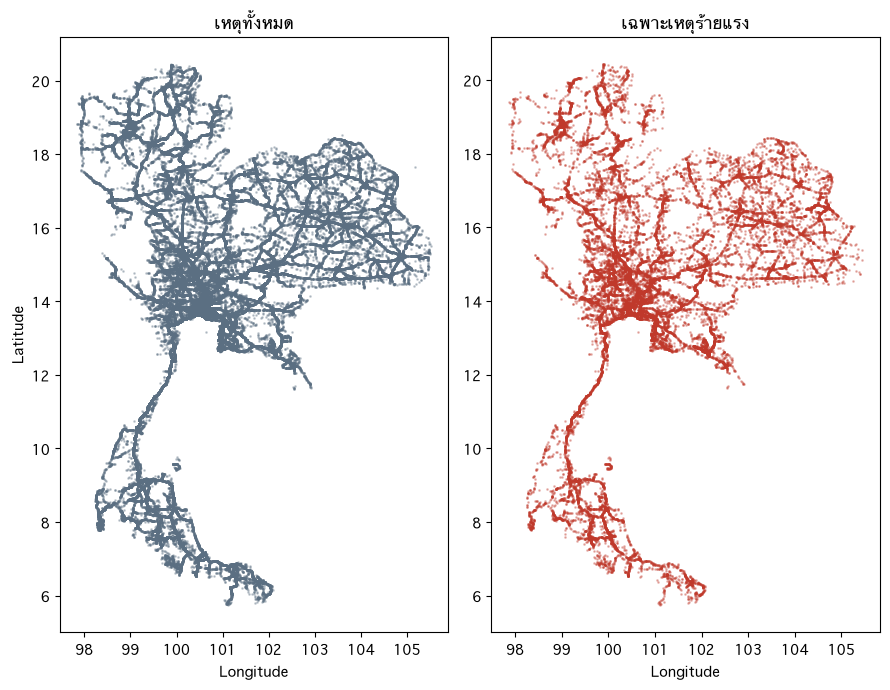

In [22]:
located = clean.dropna(subset=["lat", "lon"]).copy()
severe_rows = located.loc[located["severe"].eq(1)]

fig, axes = plt.subplots(1, 2, figsize=(9, 7))
axes[0].scatter(located["lon"], located["lat"], s=1, alpha=0.3, color="#5b6f82")
axes[0].set(title="เหตุทั้งหมด", xlabel="Longitude", ylabel="Latitude")
axes[1].scatter(severe_rows["lon"], severe_rows["lat"], s=1, alpha=0.3, color="#c0392b")
axes[1].set(title="เฉพาะเหตุร้ายแรง", xlabel="Longitude")
plt.tight_layout()
plt.show()

**อ่านภาพ:** จุดเรียงตัวตามแนวทางหลวง เพราะข้อมูลมีเฉพาะถนนของกรมทางหลวง กรมทางหลวงชนบท และการทางพิเศษ ทั้งสองภาพเข้มที่สุดรอบกรุงเทพฯ เพราะบริเวณนั้นมีเหตุมากที่สุด ภาพแบบนี้บอกได้แค่ "จำนวน" แต่บอกไม่ได้ว่าเหตุในพื้นที่นั้นร้ายแรงเป็น "สัดส่วน" เท่าไร จึงต้องคำนวณต่อในหัวข้อถัดไป

### 4.6 เกิดบ่อย กับ ร้ายแรง เป็นเรื่องเดียวกันไหม
แบ่งแผนที่เป็นช่องขนาดประมาณ 11 × 11 กม. (ปัดพิกัดเหลือทศนิยม 1 ตำแหน่ง) แล้วนับจำนวนเหตุและสัดส่วนเหตุร้ายแรงของแต่ละช่อง

In [23]:
def most_common(values):
    return values.value_counts().index[0]


located["lat_cell"] = located["lat"].round(1)
located["lon_cell"] = located["lon"].round(1)
cell_groups = located.groupby(["lat_cell", "lon_cell"])

cells = pd.DataFrame({
    "accidents": cell_groups["severe"].size(),
    "severe_rate": cell_groups["severe"].mean(),
    "province": cell_groups["province"].agg(most_common),
})
cells = cells.reset_index()

# ดูเฉพาะช่องที่มีเหตุมากพอ สัดส่วนจะได้ไม่แกว่ง
busy_cells = cells.loc[cells["accidents"] >= 200]
print("จำนวนช่องที่มีเหตุตั้งแต่ 200 ครั้ง:", len(busy_cells))

print("\n5 ช่องที่เกิดเหตุบ่อยที่สุด")
print(busy_cells.sort_values("accidents", ascending=False).head(5).round(3).to_string(index=False))

print("\n5 ช่องที่สัดส่วนเหตุร้ายแรงสูงที่สุด")
print(busy_cells.sort_values("severe_rate", ascending=False).head(5).round(3).to_string(index=False))

จำนวนช่องที่มีเหตุตั้งแต่ 200 ครั้ง: 112

5 ช่องที่เกิดเหตุบ่อยที่สุด
 lat_cell  lon_cell  accidents  severe_rate      province
     13.7     100.7       2924        0.028 กรุงเทพมหานคร
     13.8     100.4       2901        0.055 กรุงเทพมหานคร
     13.8     100.7       1633        0.031 กรุงเทพมหานคร
     13.7     100.8       1462        0.021 กรุงเทพมหานคร
     13.9     100.7       1357        0.032 กรุงเทพมหานคร

5 ช่องที่สัดส่วนเหตุร้ายแรงสูงที่สุด
 lat_cell  lon_cell  accidents  severe_rate province
     12.6     102.1        276        0.504 จันทบุรี
     16.5     104.7        223        0.408 มุกดาหาร
     12.7     102.1        217        0.406 จันทบุรี
      7.6     100.0        254        0.339   พัทลุง
      7.6     100.1        200        0.310   พัทลุง


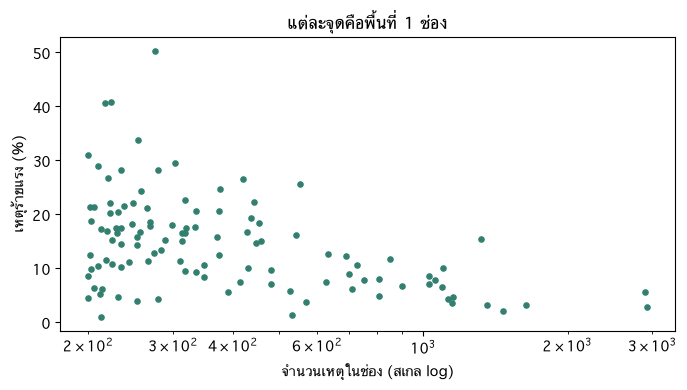

ความสัมพันธ์ระหว่างจำนวนเหตุกับสัดส่วนร้ายแรง (Spearman): -0.41


In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(busy_cells["accidents"], busy_cells["severe_rate"] * 100, s=14, color="#327f70")
ax.set_xscale("log")
ax.set(xlabel="จำนวนเหตุในช่อง (สเกล log)", ylabel="เหตุร้ายแรง (%)",
       title="แต่ละจุดคือพื้นที่ 1 ช่อง")
plt.tight_layout()
plt.show()

correlation = busy_cells["accidents"].corr(busy_cells["severe_rate"], method="spearman")
print("ความสัมพันธ์ระหว่างจำนวนเหตุกับสัดส่วนร้ายแรง (Spearman):", round(correlation, 2))

**อ่านผล:** 5 ช่องที่เกิดเหตุบ่อยที่สุดอยู่ในกรุงเทพฯ ทั้งหมด ช่องที่บ่อยที่สุดมี 2,924 เหตุ แต่ร้ายแรงเพียง 2.8% ส่วนช่องในจันทบุรีมี 276 เหตุ แต่ร้ายแรงถึง 50.4%

ค่าความสัมพันธ์ −0.41 แปลว่าพื้นที่ที่เกิดเหตุบ่อยมีแนวโน้มร้ายแรง **น้อยกว่า** ถ้าวางแผนจากจำนวนเหตุอย่างเดียว จะมองข้ามพื้นที่ที่เกิดไม่บ่อยแต่ร้ายแรง นี่คือเหตุผลที่ต้องมีตัวเลข "โอกาสร้ายแรง" แยกจาก "จำนวนเหตุ"

## 5. เตรียม feature
กฎที่ใช้เลือก feature คือ **ต้องเป็นสิ่งที่รู้ได้ก่อนเกิดเหตุ** เพราะผู้ใช้ต้องกรอกเองตอนวางแผน

### ข้อมูลที่ลองใช้ทำนาย
| ชื่อในโค้ด | ความหมาย | มาจาก |
|---|---|---|
| `vehicle` | ประเภทรถคันแรก | รถคันที่1 |
| `lat`, `lon` | พิกัดของจุดเกิดเหตุ | LATITUDE, LONGITUDE |
| `hour` | ชั่วโมงที่เกิดเหตุ | เวลา |
| `day_of_week` | วันในสัปดาห์ (0 = จันทร์) | วันที่เกิดเหตุ |
| `month` | เดือน | วันที่เกิดเหตุ |
| `festival` | ปีใหม่ / สงกรานต์ / ปกติ | วันที่เกิดเหตุ |
| `road_type` | ทางหลวง / ทางหลวงชนบท / การทางพิเศษ | สายทางหน่วยงาน |
| `weather` | สภาพอากาศ | สภาพอากาศ |
| `road_shape`, `road_slope` | รูปร่างและความลาดชันของถนน | บริเวณที่เกิดเหตุ |

**Target คือ `severe`:** 1 = ร้ายแรง, 0 = ไม่ร้ายแรง

### ข้อมูลที่ไม่ใช้ และเหตุผล
- **จำนวนผู้เสียชีวิตและผู้บาดเจ็บ:** เป็นตัวคำตอบเอง ถ้าใช้จะเท่ากับให้โมเดลเห็นเฉลย
- **ลักษณะการชน และมูลเหตุสันนิษฐาน:** รู้ได้หลังเกิดเหตุเท่านั้น ตอนวางแผนยังไม่มีข้อมูลนี้

In [25]:
def find_festival(month, day):
    # ช่วง 7 วันอันตรายโดยประมาณ
    if month == 12 and day >= 27:
        return "ปีใหม่"
    if month == 1 and day <= 4:
        return "ปีใหม่"
    if month == 4 and day >= 10 and day <= 17:
        return "สงกรานต์"
    return "ปกติ"


features_table = clean.copy()
features_table["day_of_week"] = features_table["date"].dt.day_of_week
features_table["month"] = features_table["date"].dt.month

festivals = []
for date in features_table["date"]:
    festivals.append(find_festival(date.month, date.day))
features_table["festival"] = festivals

features_table.groupby("festival")["severe"].agg(["size", "mean"]).round(3)

,size,mean
festival,,
ปกติ,129747,0.173
ปีใหม่,11193,0.271
สงกรานต์,9122,0.257


### ระวังการอ่านตัวเลขช่วงเทศกาล
ตารางข้างบนดูเหมือนช่วงเทศกาลร้ายแรงกว่าวันปกติมาก ลองแยกดูเฉพาะจักรยานยนต์กับรถประเภทอื่น

In [26]:
is_motorcycle = features_table["vehicle"].eq("รถจักรยานยนต์")

print("สัดส่วนเหตุที่รถคันแรกเป็นจักรยานยนต์")
print(is_motorcycle.groupby(features_table["festival"]).mean().round(3))
print()
print("สัดส่วนเหตุร้ายแรง เฉพาะจักรยานยนต์")
print(features_table.loc[is_motorcycle].groupby("festival")["severe"].mean().round(3))
print()
print("สัดส่วนเหตุร้ายแรง เฉพาะรถประเภทอื่น")
print(features_table.loc[~is_motorcycle].groupby("festival")["severe"].mean().round(3))

สัดส่วนเหตุที่รถคันแรกเป็นจักรยานยนต์
festival
ปกติ        0.115
ปีใหม่      0.366
สงกรานต์    0.331
Name: vehicle, dtype: float64

สัดส่วนเหตุร้ายแรง เฉพาะจักรยานยนต์
festival
ปกติ        0.498
ปีใหม่      0.388
สงกรานต์    0.393
Name: severe, dtype: float64

สัดส่วนเหตุร้ายแรง เฉพาะรถประเภทอื่น
festival
ปกติ        0.131
ปีใหม่      0.203
สงกรานต์    0.190
Name: severe, dtype: float64


**อ่านผล:** ช่วงเทศกาล เหตุที่รถคันแรกเป็นจักรยานยนต์เพิ่มจาก 11.5% เป็นประมาณ 33–37% ของเหตุทั้งหมด และจักรยานยนต์ร้ายแรงบ่อยกว่ารถอื่นอยู่แล้ว ตัวเลขรวมของช่วงเทศกาลจึงสูงขึ้นมาก

แต่ถ้าดูเฉพาะจักรยานยนต์ ช่วงเทศกาลกลับร้ายแรง **น้อยกว่า** วันปกติ (ประมาณ 39% เทียบกับ 49.8%) คำอธิบายที่เป็นไปได้คือช่วง 7 วันอันตรายมีการบันทึกเหตุละเอียดขึ้น เหตุจักรยานยนต์เล็ก ๆ จึงถูกบันทึกเข้ามามากกว่าปกติ

📌 นี่คือตัวอย่างของ **Simpson's paradox** คือภาพรวมกับภาพย่อยบอกทิศทางต่างกัน เพราะสัดส่วนของกลุ่มย่อยเปลี่ยนไป ตัวเลข "โอกาสร้ายแรง" ทั้งหมดในงานนี้จึงหมายถึงโอกาสในกลุ่ม **เหตุที่ถูกบันทึก** ซึ่งขึ้นกับวิธีบันทึกของแต่ละช่วงเวลาและพื้นที่ด้วย

## 6. แบ่งข้อมูลตามเวลา
- **Train ปี 2020–2023:** ใช้ฝึกโมเดล
- **Validation ปี 2024:** ใช้เลือกโมเดลและเลือก feature
- **Test ปี 2025–ต.ค. 2026:** ใช้ประเมินครั้งสุดท้าย หลังเลือกทุกอย่างเสร็จแล้ว

แบ่งตามเวลาเพราะตอนใช้งานจริง โมเดลต้องทำนายเหตุในอนาคตจากข้อมูลในอดีต

In [27]:
features_table["split"] = "train"
features_table.loc[features_table["year"].eq(2024), "split"] = "validation"
features_table.loc[features_table["year"].ge(2025), "split"] = "test"

categorical = ["vehicle", "festival", "road_type", "weather", "road_shape", "road_slope"]
numeric = ["hour", "day_of_week", "month", "lat", "lon"]
features = categorical + numeric
target = "severe"

# บันทึกตารางที่พร้อมใช้ฝึกโมเดล
feature_path = feature_dir / "accidents_features.csv"
features_table[["year", "split"] + features + [target]].to_csv(feature_path, index=False, encoding="utf-8-sig")
print("บันทึกแล้ว:", feature_path.relative_to(project_dir))

train = features_table.loc[features_table["split"].eq("train")]
validation = features_table.loc[features_table["split"].eq("validation")]
test = features_table.loc[features_table["split"].eq("test")]

for name, part in [("Train", train), ("Validation", validation), ("Test", test)]:
    print(name, "|", len(part), "เหตุ | ร้ายแรง", round(part[target].mean() * 100, 1), "%")

บันทึกแล้ว: data/explore_idea/severity_map/features/accidents_features.csv
Train | 84005 เหตุ | ร้ายแรง 19.5 %
Validation | 23952 เหตุ | ร้ายแรง 18.2 %
Test | 42105 เหตุ | ร้ายแรง 16.9 %


## 7. วิธีวัดผล และ baseline
เหตุร้ายแรงมีไม่ถึง 1 ใน 5 ถ้าโมเดลทายว่า "ไม่ร้ายแรง" ทุกเหตุ จะได้ accuracy เกิน 80% ทั้งที่ไม่มีประโยชน์ จึงไม่ใช้ accuracy

| Metric | ตอบคำถามอะไร | ค่าที่ดี |
|---|---|---|
| **PR-AUC** (ตัวหลัก) | โมเดลจัดให้เหตุร้ายแรงอยู่ในกลุ่มเสี่ยงสูงได้ดีแค่ไหน | ยิ่งสูงยิ่งดี ถ้าเดาสุ่มจะได้เท่ากับสัดส่วนเหตุร้ายแรง |
| ROC-AUC | สุ่มเหตุร้ายแรงกับเหตุไม่ร้ายแรงมาอย่างละ 1 เหตุ โมเดลให้คะแนนเหตุร้ายแรงสูงกว่ากี่ % ของครั้ง | ยิ่งสูงยิ่งดี เดาสุ่มได้ 0.5 |
| Brier score | เปอร์เซ็นต์ที่โมเดลบอกห่างจากผลจริงแค่ไหน | ยิ่งต่ำยิ่งดี |

**Baseline** คือวิธีง่าย ๆ ที่ไม่ใช้ ML: ใช้สัดส่วนเหตุร้ายแรงในอดีตของรถแต่ละประเภทเป็นคำตอบ ถ้าโมเดลไม่ชนะ baseline ก็ไม่จำเป็นต้องใช้โมเดล

In [28]:
def evaluate(actual, probability):
    return {
        "PR-AUC": average_precision_score(actual, probability),
        "ROC-AUC": roc_auc_score(actual, probability),
        "Brier": brier_score_loss(actual, probability),
    }


def vehicle_baseline(history, part):
    # สัดส่วนเหตุร้ายแรงของรถแต่ละประเภทในอดีต
    vehicle_rate = history.groupby("vehicle")[target].mean()
    overall_rate = history[target].mean()
    return part["vehicle"].map(vehicle_rate).fillna(overall_rate)


baseline_scores = evaluate(validation[target], vehicle_baseline(train, validation))
print("Baseline บน Validation")
for metric, value in baseline_scores.items():
    print(" ", metric, round(value, 3))

Baseline บน Validation
  PR-AUC 0.307
  ROC-AUC 0.639
  Brier 0.137


## 8. สร้างโมเดล Classification 4 แบบ
ก่อนฝึก ให้ **Pipeline** เตรียมข้อมูล 2 อย่าง โดยเรียนรู้จาก Train เท่านั้น
- **ตัวเลข:** เติมค่าว่างด้วยค่ากลาง แล้วปรับสเกลให้ใกล้กัน
- **หมวดหมู่:** แปลงเป็นคอลัมน์ 0/1 (One-Hot)

| โมเดล | เรียนรู้แบบไหน |
|---|---|
| Logistic Regression | ให้น้ำหนักแต่ละ feature แล้วรวมเป็นโอกาส เป็นโมเดลพื้นฐานที่สุด |
| Decision Tree | ตั้งเงื่อนไขทีละข้อ เช่น "เป็นจักรยานยนต์ไหม" |
| Random Forest | รวมต้นไม้หลายต้นเพื่อให้ผลนิ่งขึ้น |
| Gradient Boosting | สร้างต้นไม้ทีละต้น โดยต้นใหม่แก้จุดที่ต้นก่อนหน้าทายผิด |

In [29]:
def make_prepare(categorical_columns, numeric_columns):
    number_step = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    category_step = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([
        ("number", number_step, numeric_columns),
        ("category", category_step, categorical_columns),
    ])


estimators = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}


def build_model(name, categorical_columns, numeric_columns):
    # clone คือการทำสำเนาโมเดลเปล่า เพื่อให้ฝึกใหม่ได้ทุกครั้ง
    prepare = make_prepare(categorical_columns, numeric_columns)
    return make_pipeline(prepare, clone(estimators[name]))

In [30]:
# ฝึกด้วย Train แล้ววัดผลบน Validation
validation_rows = []
for name in estimators:
    model = build_model(name, categorical, numeric)
    model.fit(train[features], train[target])
    probability = model.predict_proba(validation[features])[:, 1]
    scores = evaluate(validation[target], probability)
    scores["Model"] = name
    validation_rows.append(scores)
    print("ฝึก", name, "แล้ว")

baseline_row = evaluate(validation[target], vehicle_baseline(train, validation))
baseline_row["Model"] = "Baseline (สัดส่วนตามประเภทรถ)"
validation_rows.append(baseline_row)

validation_scores = pd.DataFrame(validation_rows).set_index("Model").sort_values("PR-AUC", ascending=False)
validation_scores.round(3)

ฝึก Logistic Regression แล้ว


ฝึก Decision Tree แล้ว


ฝึก Random Forest แล้ว


ฝึก Gradient Boosting แล้ว


,PR-AUC,ROC-AUC,Brier
Model,,,
Gradient Boosting,0.475,0.761,0.124
Random Forest,0.444,0.745,0.128
Decision Tree,0.385,0.705,0.132
Logistic Regression,0.355,0.676,0.136
Baseline (สัดส่วนตามประเภทรถ),0.307,0.639,0.137


In [31]:
best_name = validation_scores.index[0]
print("เลือกจาก Validation:", best_name)

เลือกจาก Validation: Gradient Boosting


**อ่านตาราง:** ทุกโมเดลชนะ baseline (PR-AUC 0.307) Gradient Boosting ดีที่สุดที่ 0.475 รองลงมาคือ Random Forest ที่ 0.444 จึงเลือก Gradient Boosting

Logistic Regression ได้เพียง 0.355 เพราะโมเดลนี้ให้น้ำหนักพิกัดเป็นเส้นตรง จึงเรียนไม่ได้ว่าพื้นที่หนึ่งต่างจากพื้นที่ข้างเคียงอย่างไร ส่วนโมเดลแบบต้นไม้แบ่งแผนที่เป็นช่อง ๆ ได้เอง

## 9. ทดลอง: feature กลุ่มไหนช่วยจริง
ถอด feature ออกทีละกลุ่ม แล้วฝึกโมเดลที่เลือกใหม่ ถ้าถอดแล้ว PR-AUC ลดลงมาก แปลว่ากลุ่มนั้นสำคัญ ถ้าแทบไม่ลด แปลว่าไม่จำเป็น

การทดลองนี้ตอบคำถามสำคัญด้วยว่า **การรู้ตำแหน่งช่วยไหม** ถ้าไม่ช่วย แผนที่ก็เป็นแค่หน้าจอแสดงผล

In [32]:
feature_groups = {
    "ประเภทรถ": ["vehicle"],
    "ตำแหน่ง": ["lat", "lon"],
    "ชั่วโมง": ["hour"],
    "วัน เดือน เทศกาล": ["day_of_week", "month", "festival"],
    "ประเภทถนน": ["road_type"],
    "สภาพอากาศ": ["weather"],
    "ลักษณะถนน": ["road_shape", "road_slope"],
}


def validation_pr_auc(categorical_columns, numeric_columns):
    columns = categorical_columns + numeric_columns
    model = build_model(best_name, categorical_columns, numeric_columns)
    model.fit(train[columns], train[target])
    probability = model.predict_proba(validation[columns])[:, 1]
    return average_precision_score(validation[target], probability)


full_score = validation_pr_auc(categorical, numeric)

ablation_rows = []
for group_name, group_columns in feature_groups.items():
    kept_categorical = []
    for column in categorical:
        if column not in group_columns:
            kept_categorical.append(column)
    kept_numeric = []
    for column in numeric:
        if column not in group_columns:
            kept_numeric.append(column)
    score = validation_pr_auc(kept_categorical, kept_numeric)
    ablation_rows.append({"กลุ่มที่ถอดออก": group_name, "PR-AUC": score, "ลดลง": full_score - score})

ablation = pd.DataFrame(ablation_rows).sort_values("ลดลง", ascending=False)
print("PR-AUC เมื่อใช้ครบทุกกลุ่ม:", round(full_score, 3))
ablation.round(3)

PR-AUC เมื่อใช้ครบทุกกลุ่ม: 0.475


,กลุ่มที่ถอดออก,PR-AUC,ลดลง
0,ประเภทรถ,0.350,0.125
1,ตำแหน่ง,0.382,0.093
3,วัน เดือน เทศกาล,0.457,0.018
2,ชั่วโมง,0.468,0.007
4,ประเภทถนน,0.473,0.002
5,สภาพอากาศ,0.476,-0.001
6,ลักษณะถนน,0.477,-0.002


**อ่านตาราง**
- **ประเภทรถ** สำคัญที่สุด ถอดแล้ว PR-AUC ลดลง 0.125
- **ตำแหน่ง** สำคัญเป็นอันดับสอง ถอดแล้วลดลง 0.093 จึงตอบได้ว่าการรู้ตำแหน่งช่วยจริง แผนที่ไม่ได้เป็นแค่หน้าจอแสดงผล
- **วัน เดือน เทศกาล** และ **ชั่วโมง** ช่วยเล็กน้อย (0.018 และ 0.007)
- **สภาพอากาศ** และ **ลักษณะถนน** ไม่ช่วยเลย ถอดออกแล้วคะแนนไม่ลด

จึงตัดสภาพอากาศและลักษณะถนนออก ผู้ใช้จะกรอกน้อยลงโดยโมเดลไม่แย่ลง ส่วนประเภทถนนช่วยน้อยมาก (0.002) แต่เก็บไว้ เพราะระบบดูจากตำแหน่งได้เอง ผู้ใช้ไม่ต้องกรอก

In [33]:
# feature ชุดสุดท้าย: ตัดสภาพอากาศและลักษณะถนนออก
final_categorical = ["vehicle", "festival", "road_type"]
final_numeric = ["hour", "day_of_week", "month", "lat", "lon"]
final_features = final_categorical + final_numeric

final_score = validation_pr_auc(final_categorical, final_numeric)
print("PR-AUC ใช้ครบทุก feature:", round(full_score, 3))
print("PR-AUC ใช้ feature ชุดสุดท้าย:", round(final_score, 3))

PR-AUC ใช้ครบทุก feature: 0.475
PR-AUC ใช้ feature ชุดสุดท้าย: 0.476


## 10. ประเมินด้วย Test
ตอนนี้เลือกโมเดลและ feature เสร็จแล้ว จึงเปิดใช้ Test เป็นครั้งแรก

ก่อนประเมิน ฝึกโมเดลใหม่ด้วย Train + Validation (ปี 2020–2024) เพราะตอนเริ่มปี 2025 ข้อมูลปี 2024 เป็นอดีตที่รู้แล้ว

In [34]:
history = pd.concat([train, validation], ignore_index=True)

test_model = build_model(best_name, final_categorical, final_numeric)
test_model.fit(history[final_features], history[target])
test_probability = test_model.predict_proba(test[final_features])[:, 1]

# วิธีเทียบ 2 แบบ: ให้ทุกเหตุได้ค่าเฉลี่ยเท่ากัน และ baseline ตามประเภทรถ
same_for_all = np.full(len(test), history[target].mean())

test_rows = []
for name, probability in [("ทุกเหตุได้ค่าเฉลี่ยเท่ากัน", same_for_all),
                          ("Baseline (สัดส่วนตามประเภทรถ)", vehicle_baseline(history, test)),
                          (best_name, test_probability)]:
    scores = evaluate(test[target], probability)
    scores["วิธี"] = name
    test_rows.append(scores)

test_scores = pd.DataFrame(test_rows).set_index("วิธี")
test_scores.round(3)

,PR-AUC,ROC-AUC,Brier
วิธี,,,
ทุกเหตุได้ค่าเฉลี่ยเท่ากัน,0.169,0.500,0.141
Baseline (สัดส่วนตามประเภทรถ),0.314,0.663,0.127
Gradient Boosting,0.463,0.760,0.116


**อ่านตาราง:** บนข้อมูลปี 2025–2026 ที่โมเดลไม่เคยเห็น Gradient Boosting ได้ PR-AUC 0.463 สูงกว่า baseline ตามประเภทรถ (0.314) และสูงกว่าการให้ค่าเฉลี่ยเท่ากันทุกเหตุ (0.169) ประมาณ 2.7 เท่า คะแนนใกล้กับตอน Validation (0.476) แสดงว่าโมเดลไม่ได้จำข้อมูลเก่า

ROC-AUC 0.760 หมายความว่า ถ้าสุ่มเหตุร้ายแรงกับเหตุไม่ร้ายแรงมาอย่างละ 1 เหตุ โมเดลให้คะแนนเหตุร้ายแรงสูงกว่าประมาณ 76% ของครั้ง ถือว่าแยกได้ระดับปานกลาง ยังไม่ถึงขั้นแม่นมาก

### 10.1 เปอร์เซ็นต์ที่โมเดลบอก เชื่อได้ไหม (Calibration)
เว็บจะแสดงเปอร์เซ็นต์ให้ผู้ใช้เห็นตรง ๆ จึงต้องตรวจว่า ถ้าโมเดลบอก 30% เหตุกลุ่มนั้นร้ายแรงจริงประมาณ 30% หรือไม่

แบ่งเหตุใน Test เป็น 10 กลุ่มเท่า ๆ กัน เรียงจากโอกาสต่ำไปสูง แล้วเทียบค่าที่โมเดลบอกกับค่าจริง

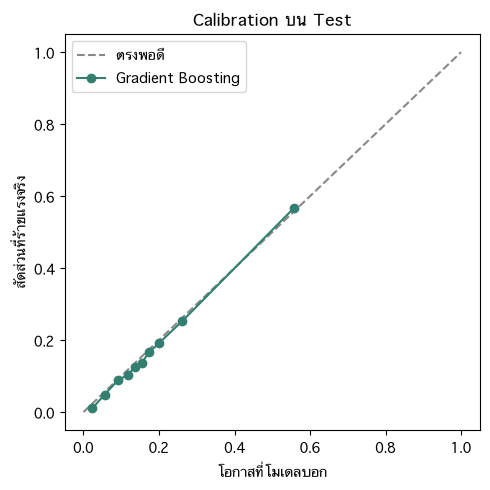

In [35]:
actual_rate, predicted_rate = calibration_curve(test[target], test_probability, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color="#888888", label="ตรงพอดี")
ax.plot(predicted_rate, actual_rate, marker="o", color="#327f70", label=best_name)
ax.set(xlabel="โอกาสที่โมเดลบอก", ylabel="สัดส่วนที่ร้ายแรงจริง", title="Calibration บน Test")
ax.legend()
plt.tight_layout()
plt.show()

In [36]:
# ตารางเดียวกับกราฟ และดูว่าเหตุร้ายแรงไปรวมอยู่ในกลุ่มเสี่ยงสูงแค่ไหน
result = pd.DataFrame({"probability": test_probability, "actual": test[target].to_numpy()})
result["risk_group"] = pd.qcut(result["probability"], 10, labels=False) + 1

risk_table = result.groupby("risk_group").agg({"probability": "mean", "actual": ["mean", "sum", "size"]})
risk_table.columns = ["โมเดลบอก", "ร้ายแรงจริง", "จำนวนเหตุร้ายแรง", "จำนวนเหตุ"]
risk_table["ส่วนแบ่งของเหตุร้ายแรงทั้งหมด"] = risk_table["จำนวนเหตุร้ายแรง"] / risk_table["จำนวนเหตุร้ายแรง"].sum()
risk_table.round(3)

,โมเดลบอก,ร้ายแรงจริง,จำนวนเหตุร้ายแรง,จำนวนเหตุ,ส่วนแบ่งของเหตุร้ายแรงทั้งหมด
risk_group,,,,,
1,0.023,0.010,43,4211,0.006
2,0.056,0.049,205,4210,0.029
3,0.091,0.088,370,4211,0.052
4,0.117,0.103,435,4210,0.061
5,0.137,0.125,527,4211,0.074
6,0.154,0.135,570,4210,0.080
7,0.173,0.166,697,4210,0.098
8,0.201,0.192,810,4211,0.114
9,0.262,0.253,1065,4210,0.150


**อ่านผล:** จุดในกราฟเกาะเส้นประเกือบทุกจุด แปลว่าเปอร์เซ็นต์ที่โมเดลบอกตรงกับความจริง เช่น กลุ่มที่ 9 โมเดลบอกเฉลี่ย 26.2% ร้ายแรงจริง 25.3% และกลุ่มที่ 10 โมเดลบอก 55.7% ร้ายแรงจริง 56.6% เว็บจึงแสดงเปอร์เซ็นต์ให้ผู้ใช้ได้

กลุ่มที่ 10 คือเหตุ 10% ที่โมเดลให้โอกาสสูงที่สุด มีเหตุร้ายแรงรวมอยู่ถึง 33.5% ของเหตุร้ายแรงทั้งหมด ส่วนกลุ่มที่ 1 ร้ายแรงจริงเพียง 1.0%

### 10.2 ถ้าใช้เป็นสัญญาณเตือน
สมมติเว็บขึ้นคำว่า "เสี่ยงสูง" เมื่อโอกาสร้ายแรงตั้งแต่ 30% ขึ้นไป (ประมาณ 2 เท่าของค่าเฉลี่ย) ดูว่าเตือนถูกและพลาดไปเท่าไร

- **Recall:** จากเหตุร้ายแรงทั้งหมด เตือนได้กี่ %
- **Precision:** จากเหตุที่เตือน ร้ายแรงจริงกี่ %

In [37]:
high_risk_threshold = 0.30
predicted_high_risk = (test_probability >= high_risk_threshold).astype(int)

matrix = confusion_matrix(test[target], predicted_high_risk)
matrix_table = pd.DataFrame(matrix,
                            index=["จริง: ไม่ร้ายแรง", "จริง: ร้ายแรง"],
                            columns=["โมเดล: ไม่เตือน", "โมเดล: เตือน"])
print(matrix_table)

true_negative, false_positive, false_negative, true_positive = matrix.ravel()
recall = true_positive / (true_positive + false_negative)
precision = true_positive / (true_positive + false_positive)
print()
print("Recall:", round(recall * 100, 1), "%")
print("Precision:", round(precision * 100, 1), "%")
print("สัดส่วนเหตุที่ถูกเตือน:", round(predicted_high_risk.mean() * 100, 1), "%")

                  โมเดล: ไม่เตือน  โมเดล: เตือน
จริง: ไม่ร้ายแรง            32694          2305
จริง: ร้ายแรง                4484          2622

Recall: 36.9 %
Precision: 53.2 %
สัดส่วนเหตุที่ถูกเตือน: 11.7 %


**อ่านผล:** เมื่อเตือนที่ 30% โมเดลเตือนถูก 2,622 เหตุ เตือนผิด 2,305 เหตุ และพลาดเหตุร้ายแรงไป 4,484 เหตุ คิดเป็น Recall 36.9% และ Precision 53.2%

Recall ที่ต่ำบอกข้อจำกัดสำคัญ คือเหตุร้ายแรงส่วนใหญ่เกิดในสถานการณ์ที่ดูไม่เสี่ยง เพราะความร้ายแรงขึ้นกับสิ่งที่ไม่มีในข้อมูลก่อนเกิดเหตุ เช่น ความเร็วขณะชน หรือการสวมหมวกกันน็อก โมเดลนี้จึงเหมาะกับการ **เปรียบเทียบพื้นที่และสถานการณ์** มากกว่าการชี้ว่าเหตุใดเหตุหนึ่งจะร้ายแรงหรือไม่

### 10.3 โมเดลใช้ feature ไหนมากที่สุด
สลับค่าของ feature ทีละตัวแบบสุ่ม แล้วดูว่า PR-AUC บน Test ลดลงเท่าไร ยิ่งลดมาก แปลว่าโมเดลพึ่ง feature นั้นมาก (Permutation importance)

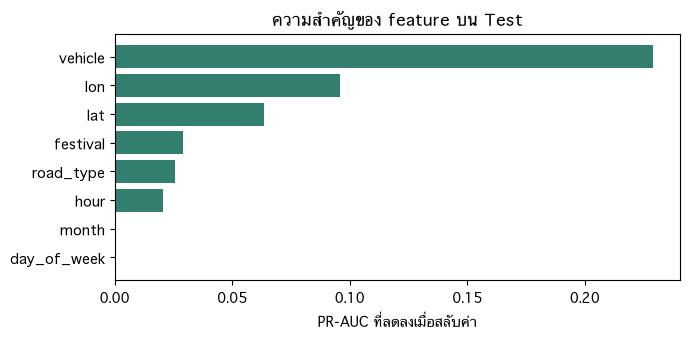

vehicle        0.229
lon            0.096
lat            0.063
festival       0.029
road_type      0.026
hour           0.020
month          0.000
day_of_week    0.000
dtype: float64


In [38]:
importance = permutation_importance(test_model, test[final_features], test[target],
                                    scoring="average_precision", n_repeats=3, random_state=42)
importance_table = pd.Series(importance.importances_mean, index=final_features).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(importance_table.index, importance_table.values, color="#327f70")
ax.set(xlabel="PR-AUC ที่ลดลงเมื่อสลับค่า", title="ความสำคัญของ feature บน Test")
plt.tight_layout()
plt.show()

print(importance_table.sort_values(ascending=False).round(3))

**อ่านกราฟ:** ประเภทรถสำคัญที่สุด (สลับค่าแล้ว PR-AUC ลดลง 0.229) รองลงมาคือพิกัด (`lon` 0.096 และ `lat` 0.063) ตรงกับผลการทดลองถอด feature ในหัวข้อ 9

`month` และ `day_of_week` แทบไม่มีผลบน Test (ประมาณ 0) รอบถัดไปอาจลองตัดออกได้ แต่รอบนี้ไม่ตัด เพราะการเลือก feature ต้องตัดสินจาก Validation ถ้าใช้ผลจาก Test มาเลือก คะแนน Test จะไม่ใช่การประเมินที่เป็นกลางอีกต่อไป

## 11. ฝึกด้วยข้อมูลทั้งหมด และบันทึกโมเดล
ประเมินเสร็จแล้ว จึงฝึกโมเดลชนิดที่เลือกด้วยข้อมูลทุกปี เพื่อให้เว็บใช้โมเดลที่เห็นข้อมูลล่าสุด

In [39]:
final_model = build_model(best_name, final_categorical, final_numeric)
final_model.fit(features_table[final_features], features_table[target])

model_path = model_dir / "severity_model.joblib"
joblib.dump(final_model, model_path)
print("บันทึกแล้ว:", model_path.relative_to(project_dir))

บันทึกแล้ว: data/explore_idea/severity_map/model/severity_model.joblib


## 12. ลองใช้โมเดล
ผู้ใช้กรอก 4 อย่าง คือ ตำแหน่ง วันที่ เวลา และประเภทรถ ส่วนประเภทถนนดูได้จากตำแหน่ง

ตัวอย่างนี้เทียบ 2 พื้นที่จริงจากหัวข้อ 4.6 คือช่องที่เกิดเหตุบ่อยที่สุด กับช่องที่สัดส่วนเหตุร้ายแรงสูงที่สุด

In [40]:
def predict_severe(model, lat, lon, date_text, hour, vehicle, road_type):
    date = pd.Timestamp(date_text)
    row = pd.DataFrame({
        "vehicle": [vehicle],
        "festival": [find_festival(date.month, date.day)],
        "road_type": [road_type],
        "hour": [hour],
        "day_of_week": [date.day_of_week],
        "month": [date.month],
        "lat": [lat],
        "lon": [lon],
    })
    return model.predict_proba(row[final_features])[0, 1]


busiest_cell = busy_cells.sort_values("accidents", ascending=False).iloc[0]
most_severe_cell = busy_cells.sort_values("severe_rate", ascending=False).iloc[0]

places = [("เกิดเหตุบ่อยที่สุด", busiest_cell), ("ร้ายแรงบ่อยที่สุด", most_severe_cell)]
scenarios = [
    ("รถยนต์นั่ง วันพุธ 14:00", "2026-11-18", 14, "รถยนต์นั่ง"),
    ("รถจักรยานยนต์ วันพุธ 14:00", "2026-11-18", 14, "รถจักรยานยนต์"),
    ("รถจักรยานยนต์ วันพุธ 21:00", "2026-11-18", 21, "รถจักรยานยนต์"),
]

example_rows = []
for place_name, cell in places:
    for scenario_name, date_text, hour, vehicle in scenarios:
        probability = predict_severe(final_model, cell["lat_cell"], cell["lon_cell"],
                                     date_text, hour, vehicle, "ทางหลวง")
        example_rows.append({
            "พื้นที่": place_name + " (" + cell["province"] + ")",
            "เหตุในอดีต": int(cell["accidents"]),
            "สถานการณ์": scenario_name,
            "โอกาสร้ายแรง (%)": round(probability * 100, 1),
        })

pd.DataFrame(example_rows)

,พื้นที่,เหตุในอดีต,สถานการณ์,โอกาสร้ายแรง (%)
0,เกิดเหตุบ่อยที่สุด (กรุงเทพมหานคร),2924,รถยนต์นั่ง วันพุธ 14:00,2.2
1,เกิดเหตุบ่อยที่สุด (กรุงเทพมหานคร),2924,รถจักรยานยนต์ วันพุธ 14:00,31.4
2,เกิดเหตุบ่อยที่สุด (กรุงเทพมหานคร),2924,รถจักรยานยนต์ วันพุธ 21:00,42.5
3,ร้ายแรงบ่อยที่สุด (จันทบุรี),276,รถยนต์นั่ง วันพุธ 14:00,29.8
4,ร้ายแรงบ่อยที่สุด (จันทบุรี),276,รถจักรยานยนต์ วันพุธ 14:00,80.3
5,ร้ายแรงบ่อยที่สุด (จันทบุรี),276,รถจักรยานยนต์ วันพุธ 21:00,83.8


**อ่านตาราง:** พื้นที่ในกรุงเทพฯ มีเหตุในอดีต 2,924 ครั้ง แต่ถ้าเป็นรถยนต์นั่งตอนบ่าย โอกาสร้ายแรงเพียง 2.2% ส่วนพื้นที่ในจันทบุรีมีเหตุเพียง 276 ครั้ง แต่สถานการณ์เดียวกันโอกาสร้ายแรง 29.8%

ประเภทรถเปลี่ยนผลได้มาก ในจุดเดียวกันที่กรุงเทพฯ จักรยานยนต์มีโอกาสร้ายแรง 31.4% และเพิ่มเป็น 42.5% ตอนกลางคืน ส่วนที่จันทบุรี จักรยานยนต์สูงถึง 80–84%

ผู้วางแผนจึงได้ข้อมูล 2 ด้านของแต่ละพื้นที่ คือเกิดบ่อยแค่ไหน (จากการนับ) และถ้าเกิดแล้วร้ายแรงแค่ไหน (จากโมเดล)

## 13. สรุป
| หัวข้อ | สิ่งที่ใช้ |
|---|---|
| โจทย์ | Classification: เหตุนี้ร้ายแรงหรือไม่ และตอบเป็นโอกาส (%) |
| ข้อมูล | อุบัติเหตุทั้งประเทศปี 2020–ต.ค. 2026 หลังคลีนเหลือ 150,062 เหตุ |
| Input feature | ประเภทรถ, พิกัด (lat, lon), ชั่วโมง, วันในสัปดาห์, เดือน, เทศกาล, ประเภทถนน |
| Model | Gradient Boosting (`HistGradientBoostingClassifier`) เลือกจาก 4 โมเดลด้วย Validation |
| Evaluation metric | PR-AUC เป็นตัวหลัก ประกอบด้วย ROC-AUC, Brier score และ Calibration |
| ผลบน Test (ปี 2025–2026) | PR-AUC 0.463, ROC-AUC 0.760, Brier 0.116 |

### สิ่งที่พบ
1. **โมเดลชนะวิธีง่าย ๆ:** PR-AUC 0.463 เทียบกับ baseline ตามประเภทรถ 0.314
2. **ตำแหน่งช่วยจริง:** ถอดพิกัดออกแล้ว PR-AUC บน Validation ลดจาก 0.475 เหลือ 0.382
3. **เปอร์เซ็นต์เชื่อได้:** ค่าที่โมเดลบอกตรงกับสัดส่วนจริงเกือบทุกกลุ่ม
4. **เกิดบ่อยไม่ได้แปลว่าร้ายแรง:** พื้นที่ที่เกิดเหตุบ่อยมีแนวโน้มร้ายแรงน้อยกว่า (Spearman −0.41)
5. **สภาพอากาศและลักษณะถนนไม่ช่วยทำนาย:** จึงตัดออก ผู้ใช้กรอกน้อยลง

### ข้อจำกัด
- **ไม่ได้บอกโอกาสเกิดอุบัติเหตุ:** บอกได้เฉพาะ "ถ้าเกิดเหตุแล้ว ร้ายแรงไหม" เพราะไม่มีข้อมูลปริมาณรถ
- **ขึ้นกับวิธีบันทึกเหตุ:** บางพื้นที่และบางหน่วยงานบันทึกเหตุเล็กน้อยไม่ครบ สัดส่วนร้ายแรงของพื้นที่นั้นจะสูงเกินจริง เช่น ทางหลวงชนบท 43% เทียบกับทางพิเศษ 0.8%
- **เป็นความสัมพันธ์ ไม่ใช่สาเหตุ:** โมเดลบอกว่าอะไรมาคู่กับเหตุร้ายแรง ไม่ได้พิสูจน์ว่าสิ่งนั้นทำให้ร้ายแรง
- **จับเหตุร้ายแรงได้ไม่ครบ:** ที่เกณฑ์เตือน 30% จับได้ 36.9% ของเหตุร้ายแรง จึงเหมาะกับการเปรียบเทียบพื้นที่ มากกว่าการชี้เหตุรายครั้ง
- **มีเฉพาะถนนของ 3 หน่วยงาน:** กรมทางหลวง กรมทางหลวงชนบท และการทางพิเศษ ไม่มีถนนในเมืองและถนนท้องถิ่น

### ไฟล์ที่ notebook นี้สร้าง
| ไฟล์ | ใช้ทำอะไร |
|---|---|
| `data/explore_idea/severity_map/clean/accidents_clean.csv` | ข้อมูลที่คลีนแล้ว หนึ่งแถวคือหนึ่งเหตุ |
| `data/explore_idea/severity_map/features/accidents_features.csv` | ตารางที่พร้อมใช้ฝึกโมเดล พร้อมคอลัมน์บอกว่าอยู่ชุด train, validation หรือ test |
| `data/explore_idea/severity_map/model/severity_model.joblib` | โมเดลที่ฝึกด้วยข้อมูลทั้งหมด สำหรับเว็บ |

### ลองใช้ผ่านเว็บ
รันคำสั่งนี้จากโฟลเดอร์โปรเจกต์ แล้วคลิกจุดบนแผนที่

```
uv run streamlit run app/severity_map_app.py
```